In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [4]:
df = pd.read_csv('/content/bus_journey_dataset.csv')
print("Shape:", df.shape)
print("\nMissing values:\n", df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())

df = df.drop_duplicates()

Shape: (500, 12)

Missing values:
 Journey_ID            0
Route                 0
Scheduled_Time        0
Actual_Time           0
Distance              0
Traffic               0
Weather               0
Number_of_Stops       0
Scheduled_Duration    0
Actual_Duration       0
Delay_Minutes         0
On_Time               0
dtype: int64

Duplicate rows: 0


In [6]:
def time_to_minutes(x):
    h, m = map(int, x.split(":"))
    return h * 60 + m

df["Scheduled_Minutes"] = df["Scheduled_Time"].apply(time_to_minutes)
df["Actual_Minutes"] = df["Actual_Time"].apply(time_to_minutes)

In [7]:
df["Start_Delay_Minutes"] = (
    df["Actual_Minutes"] - df["Scheduled_Minutes"]
)
df.loc[df["Start_Delay_Minutes"] < -720, "Start_Delay_Minutes"] += 1440
df.loc[df["Start_Delay_Minutes"] > 720, "Start_Delay_Minutes"] -= 1440

In [8]:
def time_period(hour):
    if 6 <= hour < 10:
        return "Morning Peak"
    elif 10 <= hour < 16:
        return "Afternoon"
    elif 16 <= hour < 20:
        return "Evening Peak"
    else:
        return "Night"

df["Hour"] = df["Scheduled_Minutes"] // 60
df["Time_Period"] = df["Hour"].apply(time_period)

In [9]:
print("\nDescriptive statistics:")
print(df[["Distance", "Number_of_Stops",
          "Scheduled_Duration", "Actual_Duration",
          "Delay_Minutes"]].describe())


Descriptive statistics:
         Distance  Number_of_Stops  Scheduled_Duration  Actual_Duration  \
count  500.000000       500.000000          500.000000        500.00000   
mean    16.370800        18.774000           62.731000         83.34300   
std      6.940849         6.628635           16.356325         18.85575   
min      4.000000         8.000000           28.100000         38.80000   
25%     10.325000        13.000000           49.750000         68.57500   
50%     16.800000        19.000000           63.350000         84.15000   
75%     22.325000        24.000000           75.900000         98.10000   
max     28.000000        30.000000           94.000000        130.10000   

       Delay_Minutes  
count     500.000000  
mean       20.612000  
std         8.300316  
min        -1.000000  
25%        15.000000  
50%        20.000000  
75%        25.250000  
max        50.000000  


In [10]:
route_summary = df.groupby("Route").agg(
    Journeys=("Journey_ID", "count"),
    Avg_Delay=("Delay_Minutes", "mean"),
    Median_Delay=("Delay_Minutes", "median"),
    On_Time_Percent=("On_Time", lambda x: (x == "Yes").mean()*100)
).sort_values("Avg_Delay", ascending=False)

print("\nRoute-level punctuality:")
print(route_summary.round(2))


Route-level punctuality:
       Journeys  Avg_Delay  Median_Delay  On_Time_Percent
Route                                                    
R6           49      24.90          24.0             0.00
R8           69      23.41          23.0             1.45
R4           56      23.09          22.0             0.00
R5           66      20.36          21.0             3.03
R2           50      19.98          18.0             0.00
R7           55      18.69          19.0             7.27
R3           70      18.33          18.0             4.29
R1           85      17.93          17.0             2.35


In [12]:
persistent_routes = route_summary[
    (route_summary["Avg_Delay"] > df["Delay_Minutes"].mean()) &
    (route_summary["On_Time_Percent"] < 60)
]
print("\nRoutes with persistent delays:")
print(persistent_routes.round(2))


Routes with persistent delays:
       Journeys  Avg_Delay  Median_Delay  On_Time_Percent
Route                                                    
R6           49      24.90          24.0             0.00
R8           69      23.41          23.0             1.45
R4           56      23.09          22.0             0.00


In [13]:
traffic_summary = df.groupby("Traffic")["Delay_Minutes"].agg(
    ["mean", "median", "count"]
).sort_values("mean", ascending=False)

weather_summary = df.groupby("Weather")["Delay_Minutes"].agg(
    ["mean", "median", "count"]
).sort_values("mean", ascending=False)

print("\nTraffic effect:")
print(traffic_summary.round(2))

print("\nWeather effect:")
print(weather_summary.round(2))


Traffic effect:
            mean  median  count
Traffic                        
Very High  32.95    33.0     55
High       24.58    24.0    125
Medium     18.49    18.0    181
Low        14.93    15.0    139

Weather effect:
             mean  median  count
Weather                         
Heavy Rain  27.65    27.0     49
Rain        22.61    22.0    112
Cloudy      20.20    20.0    129
Clear       18.16    18.0    210


In [14]:
time_summary = df.groupby("Time_Period")["Delay_Minutes"].agg(
    ["mean", "median", "count"]
).sort_values("mean", ascending=False)

print("\nTime-of-day analysis:")
print(time_summary.round(2))


Time-of-day analysis:
               mean  median  count
Time_Period                       
Evening Peak  24.11    23.0    114
Morning Peak  22.15    22.0    126
Night         19.87    20.0     90
Afternoon     17.52    17.0    170


In [15]:
sns.set_theme(style="whitegrid")

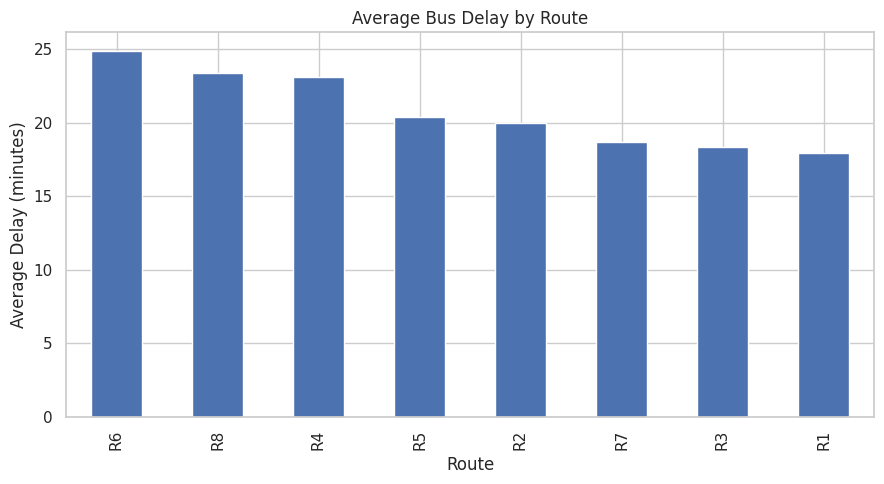

In [16]:
plt.figure(figsize=(9,5))
route_summary["Avg_Delay"].plot(kind="bar")
plt.title("Average Bus Delay by Route")
plt.xlabel("Route")
plt.ylabel("Average Delay (minutes)")
plt.tight_layout()
plt.show()

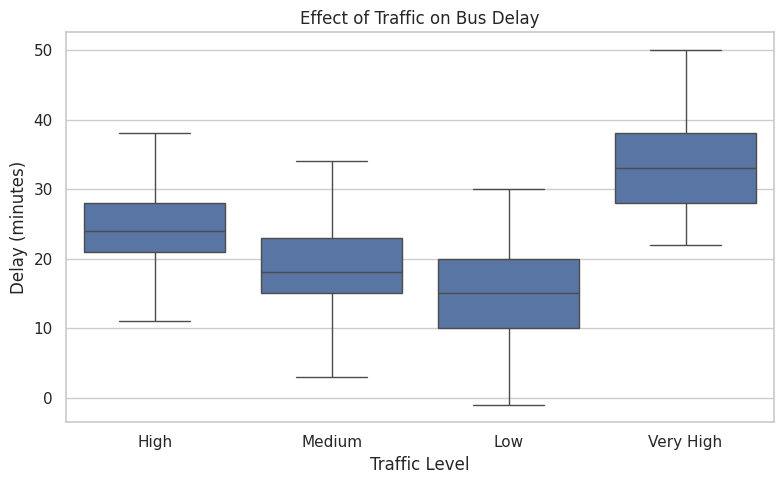

In [17]:
plt.figure(figsize=(8,5))
sns.boxplot(data=df, x="Traffic", y="Delay_Minutes")
plt.title("Effect of Traffic on Bus Delay")
plt.xlabel("Traffic Level")
plt.ylabel("Delay (minutes)")
plt.tight_layout()
plt.show()

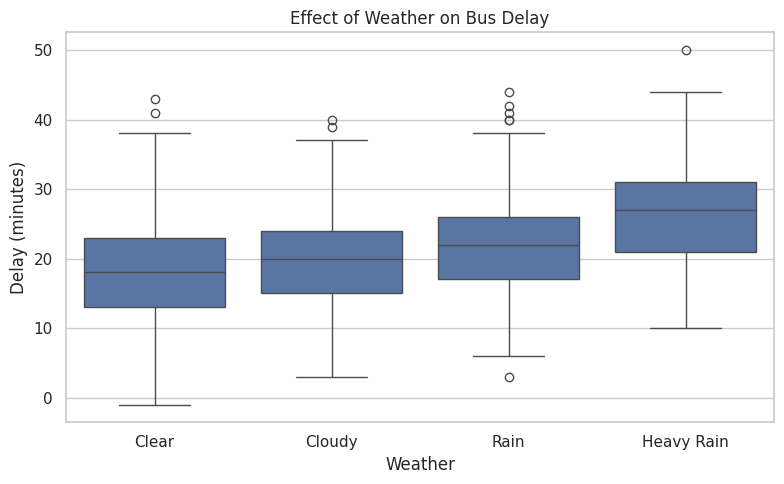

In [18]:
plt.figure(figsize=(8,5))
sns.boxplot(data=df, x="Weather", y="Delay_Minutes")
plt.title("Effect of Weather on Bus Delay")
plt.xlabel("Weather")
plt.ylabel("Delay (minutes)")
plt.tight_layout()
plt.show()

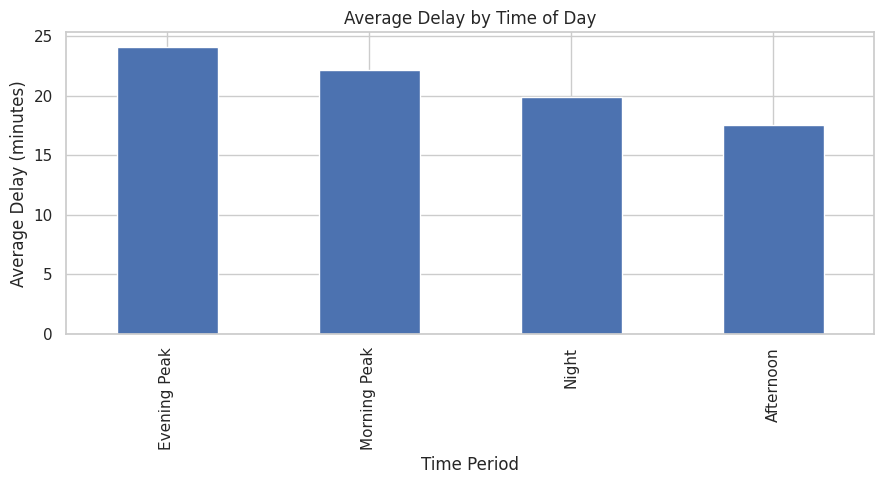

In [19]:
plt.figure(figsize=(9,5))
time_summary["mean"].plot(kind="bar")
plt.title("Average Delay by Time of Day")
plt.xlabel("Time Period")
plt.ylabel("Average Delay (minutes)")
plt.tight_layout()
plt.show()

In [20]:
features = [
    "Route", "Distance", "Traffic", "Weather",
    "Number_of_Stops", "Scheduled_Duration", "Hour"
]

X = df[features]
y = df["Delay_Minutes"]

categorical_features = ["Route", "Traffic", "Weather"]
numeric_features = [
    "Distance", "Number_of_Stops",
    "Scheduled_Duration", "Hour"
]

preprocessor = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
    ("num", "passthrough", numeric_features)
])

model = Pipeline([
    ("preprocessor", preprocessor),
    ("random_forest", RandomForestRegressor(
        n_estimators=200,
        max_depth=12,
        random_state=42
    ))
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

model.fit(X_train, y_train)
predictions = model.predict(X_test)

In [21]:
mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))
r2 = r2_score(y_test, predictions)

print("\n--- RANDOM FOREST MODEL RESULTS ---")
print("MAE :", round(mae, 2), "minutes")
print("RMSE:", round(rmse, 2), "minutes")
print("R2  :", round(r2, 3))


--- RANDOM FOREST MODEL RESULTS ---
MAE : 3.62 minutes
RMSE: 4.58 minutes
R2  : 0.707


In [22]:
print("\n--- PRACTICAL ACTION PLAN ---")
print("1. Add extra buses during high-delay peak periods.")
print("2. Increase schedule buffers on consistently delayed routes.")
print("3. Monitor high and very-high traffic corridors.")
print("4. Introduce weather-based operational adjustments.")
print("5. Review routes with low on-time percentages.")
print("6. Use GPS data continuously to update delay predictions.")
print("7. Optimize stop spacing and dwell time on heavily delayed routes.")


--- PRACTICAL ACTION PLAN ---
1. Add extra buses during high-delay peak periods.
2. Increase schedule buffers on consistently delayed routes.
3. Monitor high and very-high traffic corridors.
4. Introduce weather-based operational adjustments.
5. Review routes with low on-time percentages.
6. Use GPS data continuously to update delay predictions.
7. Optimize stop spacing and dwell time on heavily delayed routes.
